# M5 — LSTM Encoder–Decoder Forecaster (train ≤ d_1553, test d_1554 – d_1941)

A **global** LSTM: one network, trained on all 30,490 item-store series, that forecasts **28 days at a time**.

```
 past 112 days ──► [ LSTM encoder ] ──(hidden state)──► [ LSTM decoder ] ──► 28 daily forecasts
 (sales + calendar + price)                          (future calendar + price, all known in advance)
```

This is a copy of `SimpleNN.ipynb` with two changes:
1. **Extra metrics:** R², RMSE and MAPE are reported next to WRMSSE.
2. **New split, no validation set:** the model is trained only on days up to d_1553 and tested on d_1554 – d_1941.

**Design choices (based on the EDA in `ExploratoryAnalysis.ipynb`)**
| EDA finding | Design choice |
|---|---|
| Sales are sparse counts (most days are 0) | Poisson loss; `softplus` output keeps forecasts ≥ 0 |
| Series range from ~0.1 to 100+ units/day | Each window is divided by its own mean sales (the scale) and multiplied back on output |
| Strong weekday pattern; specific events (Thanksgiving, Labor Day) | Weekday and event-name **embeddings** for every day, past and future |
| SNAP lifts FOODS by 10–30% depending on state | SNAP flag for the series' own state |
| Items share patterns within department/store | Learned **embeddings** for item, dept, category, store, state |
| Store-level jumps make old history less relevant | Train only on windows from the last 3 years before the cutoff |

**Evaluation split**
| Period | Days | Used for |
|---|---|---|
| Train | d_1 – d_1553 | fitting the network (fixed number of epochs, no early stopping) |
| **Test** | **d_1554 – d_1941 (388 days)** | **all metrics reported below** |

**How the 388-day test is forecast:** the model's horizon is 28 days, so the test period is covered by **rolling-origin forecasts**.
The weights stay frozen after training on data up to d_1553. At each origin (d_1553, d_1581, …, d_1917) the model gets the *actual* sales history up to that day
and forecasts the next 28 days. That gives 13 full blocks plus a final 24-day block. The baselines are rolled forward the same way.

## 1. Setup

In [1]:
import time
import numpy as np
import pandas as pd
import scipy.sparse as sp
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

import os
DATA = next(d for d in ("..", ".", "m5-forecasting-accuracy")
            if os.path.isfile(os.path.join(d, "calendar.csv")))   # repo root when run from notebooks/
OUT = "outputs"
import os; os.makedirs(OUT, exist_ok=True)

SEED = 42
np.random.seed(SEED); torch.manual_seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device, torch.cuda.get_device_name(0) if device.type == "cuda" else "")

# ---- hyper-parameters ----
ENC_LEN = 112        # days of history the encoder sees (16 weeks)
HORIZON = 28         # days forecast per model call
HIDDEN = 128         # LSTM hidden size
LAYERS = 2
DROPOUT = 0.2
BATCH = 1024
STEPS_PER_EPOCH = 250
EPOCHS = 25          # fixed: there is no validation set for early stopping
LR = 2e-3
TRAIN_YEARS = 3      # sample training windows only from the most recent N years

# ---- split (0-based day indices: d_k -> k-1) ----
TRAIN_END = 1553     # training = d_1 .. d_1553
TEST_END  = 1941     # test     = d_1554 .. d_1941
TEST_LEN  = TEST_END - TRAIN_END
ORIGINS = list(range(TRAIN_END, TEST_END, HORIZON))      # rolling forecast origins
print(f"test: {TEST_LEN} days, {len(ORIGINS)} rolling origins (last block = {TEST_END - ORIGINS[-1]} days)")

device: cuda NVIDIA GeForce RTX 4060 Ti
test: 388 days, 14 rolling origins (last block = 24 days)


## 2. Load data

In [2]:
id_cols = ["id", "item_id", "dept_id", "cat_id", "store_id", "state_id"]
header = pd.read_csv(f"{DATA}/sales_train_evaluation.csv", nrows=0).columns
day_cols = [c for c in header if c.startswith("d_")]
sales = pd.read_csv(f"{DATA}/sales_train_evaluation.csv",
                    dtype={**{c: "category" for c in id_cols[1:]}, **{d: "int16" for d in day_cols}})
calendar = pd.read_csv(f"{DATA}/calendar.csv", parse_dates=["date"])
prices = pd.read_csv(f"{DATA}/sell_prices.csv")

Y = sales[day_cols].to_numpy().astype(np.float32)          # (N series, 1941 days)
N, T_obs = Y.shape
T_all = len(calendar)                                       # 1969 days incl. 28 future days
print(f"{N:,} series, {T_obs} observed days, {T_all} calendar days")

30,490 series, 1941 observed days, 1969 calendar days


## 3. Features
**Per day (shared by all series):** weekday, month (sin/cos), time trend, event name (embedding).  
**Per state per day:** SNAP flag.  
**Per series per day:** price relative to the item's average price, week-over-week price change, and an *on sale* flag (whether a price exists that day).  
**Static per series:** item, dept, category, store and state IDs → embeddings.

In [3]:
# --- calendar features (T_all, ...) ---
dow = ((calendar["wday"].to_numpy() - 1) % 7).astype(np.int64)      # 0..6
m = calendar["month"].to_numpy()
cal_num = np.stack([np.sin(2*np.pi*m/12), np.cos(2*np.pi*m/12),
                    np.arange(T_all) / T_all], axis=1).astype(np.float32)
event_codes = pd.Categorical(calendar["event_name_1"])
event = (event_codes.codes + 1).astype(np.int64)                      # 0 = no event
N_EVENTS = len(event_codes.categories) + 1
snap = calendar[["snap_CA", "snap_TX", "snap_WI"]].to_numpy().T.astype(np.float32)   # (3, T_all)

# --- static IDs ---
static = {c: sales[c].cat.codes.to_numpy().astype(np.int64) for c in ["item_id", "dept_id", "cat_id", "store_id", "state_id"]}
static_card = {c: len(sales[c].cat.categories) for c in static}
state_order = list(sales["state_id"].cat.categories)
assert state_order == ["CA", "TX", "WI"], state_order

# --- prices: weekly -> daily matrix (N, T_all) ---
week_cols = np.sort(calendar["wm_yr_wk"].unique())
key = sales["store_id"].astype(str) + "|" + sales["item_id"].astype(str)
pw = (prices.assign(key=prices["store_id"] + "|" + prices["item_id"])
             .pivot(index="key", columns="wm_yr_wk", values="sell_price")
             .reindex(index=key.values, columns=week_cols))
week_pos = pd.Index(week_cols).get_indexer(calendar["wm_yr_wk"])
price = pw.to_numpy(dtype=np.float32)[:, week_pos]                    # (N, T_all), NaN = not on sale
on_sale = (~np.isnan(price)).astype(np.float32)
price_rel = np.nan_to_num(price / np.nanmean(price, axis=1, keepdims=True), nan=0.0).astype(np.float32)
price_lag7 = np.concatenate([price_rel[:, :7], price_rel[:, :-7]], axis=1)
price_chg = np.where((price_rel > 0) & (price_lag7 > 0), price_rel / np.where(price_lag7 > 0, price_lag7, 1) - 1, 0).astype(np.float32)

first_sale = (Y > 0).argmax(axis=1)
print("price matrix:", price.shape, "| share of days on sale:", f"{on_sale[:, :T_obs].mean():.1%}")

price matrix: (30490, 1969) | share of days on sale: 79.2%


## 4. Metrics
**WRMSSE (official M5 accuracy metric)**
- **RMSSE**: the RMSE of a forecast divided by the RMSE of a naive "yesterday's value" forecast on that series' own history (counted from its first sale, using history up to d_1553).
- The score is computed on **42,840 series across 12 aggregation levels**, from the overall total down to individual item-store series.
- Each series is **weighted by its revenue over the last 28 training days** (d_1526 – d_1553), and each level counts 1/12.
- A WRMSSE below 1 means the forecast beats the naive benchmark. Lower is better. Here it is averaged over all 388 test days.

**R², RMSE, MAPE**, computed at two levels:
- **Item-store**: over every (series, day) cell of the test period. MAPE is undefined when actual sales are 0, and most cells are 0, so it is computed only on cells with actual sales > 0.
- **Total**: on total daily sales across all stores (388 values). This is where MAPE is easiest to interpret.
  Christmas Day (d_1792) is left out of the total MAPE only: stores are closed and total sales are ~14 units, so any forecast gives a percentage error in the thousands that would swamp the average.

In [4]:
class WRMSSE:
    LEVELS = [[], ["state_id"], ["store_id"], ["cat_id"], ["dept_id"], ["state_id", "cat_id"],
              ["state_id", "dept_id"], ["store_id", "cat_id"], ["store_id", "dept_id"],
              ["item_id"], ["item_id", "state_id"], ["item_id", "store_id"]]

    def __init__(self, sales, Y, price, hist_end):
        mats = []
        for lv in self.LEVELS:
            codes = (np.zeros(len(sales), dtype=np.int64) if not lv
                     else sales.groupby(lv, observed=True).ngroup().to_numpy())
            mats.append(sp.csr_matrix((np.ones(len(sales)), (codes, np.arange(len(sales))))))
        self.S = sp.vstack(mats).tocsr().astype(np.float64)              # (42840, N)
        self.level_of = np.concatenate([[i] * m.shape[0] for i, m in enumerate(mats)])

        H = self.S @ Y[:, :hist_end].astype(np.float64)                  # aggregated history
        started = np.maximum.accumulate(H > 0, axis=1)
        d = np.diff(H, axis=1) ** 2
        mask = started[:, 1:]
        self.scale = (d * mask).sum(1) / np.maximum(mask.sum(1), 1)

        rev = (Y[:, hist_end-28:hist_end] * np.nan_to_num(price[:, hist_end-28:hist_end])).sum(1)
        rev_agg = self.S @ rev
        w = np.zeros_like(rev_agg)
        for i in range(len(self.LEVELS)):
            sel = self.level_of == i
            w[sel] = rev_agg[sel] / rev_agg[sel].sum() / len(self.LEVELS)
        self.w = w
        self.hist_end = hist_end

    def score(self, pred, actual, by_level=False):
        err = ((self.S @ (pred - actual).astype(np.float64)) ** 2).mean(1)
        rmsse = np.sqrt(err / np.maximum(self.scale, 1e-12))
        if by_level:
            return pd.Series([(self.w * rmsse)[self.level_of == i].sum() * 12 for i in range(12)],
                             index=["Total", "State", "Store", "Category", "Dept", "State×Cat", "State×Dept",
                                    "Store×Cat", "Store×Dept", "Item", "Item×State", "Item×Store"], name="RMSSE (level)")
        return float((self.w * rmsse).sum())

def regression_metrics(pred, actual, mape_mask=None):
    """RMSE, R² and MAPE (%, on non-zero actuals only, optionally restricted by mape_mask) over all cells."""
    p, a = np.ravel(pred).astype(np.float64), np.ravel(actual).astype(np.float64)
    rmse = np.sqrt(np.mean((p - a) ** 2))
    r2 = 1 - np.sum((a - p) ** 2) / np.sum((a - a.mean()) ** 2)
    nz = (a > 0) if mape_mask is None else (a > 0) & np.ravel(mape_mask)
    mape = 100 * np.mean(np.abs(a[nz] - p[nz]) / a[nz])
    return rmse, r2, mape

IS_XMAS = (calendar["date"].dt.strftime("%m-%d") == "12-25").to_numpy()

def evaluate(pred, actual=None, days=None):
    """days: slice of test-day positions (defaults to the whole test period)."""
    actual = Y_test if actual is None else actual
    days = slice(0, TEST_LEN) if days is None else days
    rmse, r2, mape = regression_metrics(pred, actual)
    open_days = ~IS_XMAS[TRAIN_END:TEST_END][days]
    t_rmse, t_r2, t_mape = regression_metrics(pred.sum(0), actual.sum(0), mape_mask=open_days)
    return {"WRMSSE": wr_test.score(pred, actual),
            "RMSE": rmse, "R²": r2, "MAPE % (sales>0)": mape,
            "Total RMSE": t_rmse, "Total R²": t_r2, "Total MAPE % (excl. Xmas)": t_mape}

def rolling(forecast_fn):
    """Stitch 28-day forecasts made at each origin (using actual history up to it) into one (N, TEST_LEN) array."""
    return np.concatenate([forecast_fn(o)[:, :min(HORIZON, TEST_END - o)] for o in ORIGINS], axis=1)

wr_test = WRMSSE(sales, Y, price, TRAIN_END)
Y_test = Y[:, TRAIN_END:TEST_END]
print("Y_test:", Y_test.shape)

Y_test: (30490, 388)


### Baselines
Simple benchmarks that any model, including the team's regression and XGBoost models, should beat.

In [5]:
def baselines(end):
    hist = Y[:, :end]
    return {
        "Naive (repeat last day)": np.repeat(hist[:, -1:], HORIZON, 1),
        "Seasonal naive (repeat last week)": np.tile(hist[:, -7:], 4),
        "28-day moving average": np.repeat(hist[:, -28:].mean(1, keepdims=True), HORIZON, 1),
    }

baseline_preds = {name: rolling(lambda o, n=name: baselines(o)[n]) for name in baselines(TRAIN_END)}
results = {name: evaluate(p) for name, p in baseline_preds.items()}
pd.DataFrame(results).T.style.format("{:.4f}")

,WRMSSE,RMSE,R²,MAPE % (sales>0),Total RMSE,Total R²,Total MAPE % (excl. Xmas)
Naive (repeat last day),1.4075,2.8561,0.3790,83.4165,8940.5520,-0.7548,15.7723
Seasonal naive (repeat last week),0.9743,2.8755,0.3706,85.3033,4714.3357,0.5121,8.7413
28-day moving average,1.0829,2.3536,0.5783,60.3431,6553.9400,0.0570,12.4427


## 5. Training windows, sampled on the GPU
All feature arrays (about 1 GB) are copied to the GPU once. Each training batch picks random series and random **cutoff days**, then gathers the 112 history days plus the 28 target days with indexing. This avoids building millions of window copies up front.

Constraints on each window:
- The target window must end on or before `TRAIN_END` (d_1553), so no test data leaks into training.
- The cutoff must come at least 28 days after the item's first sale.

In [6]:
g = lambda a, dt=torch.float32: torch.as_tensor(a, dtype=dt, device=device)
Yg, PRICE_REL, PRICE_CHG, ON_SALE = g(Y), g(price_rel), g(price_chg), g(on_sale)
DOW, EVENT, CALNUM, SNAP = g(dow, torch.long), g(event, torch.long), g(cal_num), g(snap)
STATIC = {c: g(v, torch.long) for c, v in static.items()}

def make_batch(idx, cutoff):
    """idx: (B,) series; cutoff: (B,) index of last observed day. Returns model inputs + target."""
    t = cutoff[:, None] + torch.arange(-ENC_LEN + 1, HORIZON + 1, device=device)[None]   # (B, L+H)
    rows = idx[:, None]
    y_all = Yg[rows, t.clamp(max=T_obs - 1)]
    y_enc = y_all[:, :ENC_LEN]
    scale = 1.0 + y_enc.mean(1, keepdim=True)                                          # (B,1)
    st = STATIC["state_id"][idx]
    dyn = torch.stack([PRICE_REL[rows, t], PRICE_CHG[rows, t], ON_SALE[rows, t],
                       SNAP[st[:, None], t]], dim=-1)
    dyn = torch.cat([dyn, CALNUM[t]], dim=-1)                                           # (B, L+H, 7)
    return dict(y_enc=y_enc / scale, dyn=dyn, dow=DOW[t], event=EVENT[t],
                static={c: v[idx] for c, v in STATIC.items()}, scale=scale), y_all[:, ENC_LEN:]

train_lo = np.maximum(np.maximum(ENC_LEN - 1, first_sale + 28), TRAIN_END - HORIZON - 365 * TRAIN_YEARS)
train_hi = TRAIN_END - HORIZON - 1                         # last cutoff whose targets end at TRAIN_END
eligible = np.where(train_lo <= train_hi)[0]
LO, ELIG = g(train_lo, torch.long), g(eligible, torch.long)
print(f"{len(eligible):,} of {N:,} series eligible for training")

def sample_batch(B=BATCH):
    idx = ELIG[torch.randint(len(ELIG), (B,), device=device)]
    lo = LO[idx]
    cutoff = lo + (torch.rand(B, device=device) * (train_hi - lo + 1)).long()
    return make_batch(idx, cutoff)

29,916 of 30,490 series eligible for training


## 6. Model

In [7]:
class LSTMForecaster(nn.Module):
    def __init__(self, static_card, n_events, hidden=HIDDEN, layers=LAYERS, dropout=DROPOUT):
        super().__init__()
        emb_dim = {"item_id": 16, "dept_id": 4, "cat_id": 2, "store_id": 4, "state_id": 2}
        self.static_emb = nn.ModuleDict({c: nn.Embedding(static_card[c], emb_dim[c]) for c in static_card})
        self.dow_emb = nn.Embedding(7, 4)
        self.event_emb = nn.Embedding(n_events, 4)
        s_dim, d_dim = sum(emb_dim.values()), 7 + 4 + 4
        self.encoder = nn.LSTM(1 + d_dim + s_dim, hidden, layers, batch_first=True, dropout=dropout)
        self.decoder = nn.LSTM(d_dim + s_dim, hidden, layers, batch_first=True, dropout=dropout)
        self.head = nn.Sequential(nn.Linear(hidden, hidden // 2), nn.ReLU(), nn.Linear(hidden // 2, 1))

    def forward(self, b):
        s = torch.cat([self.static_emb[c](b["static"][c]) for c in self.static_emb], -1)       # (B, s_dim)
        d = torch.cat([b["dyn"], self.dow_emb(b["dow"]), self.event_emb(b["event"])], -1)      # (B, L+H, d_dim)
        s = s[:, None].expand(-1, d.shape[1], -1)
        enc_in = torch.cat([b["y_enc"][..., None], d[:, :ENC_LEN], s[:, :ENC_LEN]], -1)
        _, state = self.encoder(enc_in)
        out, _ = self.decoder(torch.cat([d[:, ENC_LEN:], s[:, ENC_LEN:]], -1), state)
        rate = F.softplus(self.head(out).squeeze(-1))                                          # (B, H) in scaled units
        return rate * b["scale"]                                                                # back to units

model = LSTMForecaster(static_card, N_EVENTS).to(device)
print(f"{sum(p.numel() for p in model.parameters()):,} parameters")

499,193 parameters


## 7. Train
The loss is Poisson negative log-likelihood on unit counts. There is no validation set, so the model trains for a fixed `EPOCHS` with a one-cycle learning-rate schedule, and the **final** weights are used. The test period is not looked at during training.

In [8]:
@torch.no_grad()
def predict(cutoff_day, bs=4096):
    """Forecast the 28 days after day index `cutoff_day` (exclusive end of history) for all series."""
    model.eval()
    out = []
    for i in range(0, N, bs):
        idx = torch.arange(i, min(i + bs, N), device=device)
        b, _ = make_batch(idx, torch.full_like(idx, cutoff_day - 1))
        out.append(model(b).cpu().numpy())
    model.train()
    return np.concatenate(out)

opt = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=1e-5)
sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=LR, total_steps=EPOCHS * STEPS_PER_EPOCH)
history = []

t0 = time.time()
for epoch in range(1, EPOCHS + 1):
    losses = []
    for _ in range(STEPS_PER_EPOCH):
        b, y = sample_batch()
        loss = F.poisson_nll_loss(model(b), y, log_input=False)
        opt.zero_grad(); loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        opt.step(); sched.step()
        losses.append(loss.item())
    history.append({"epoch": epoch, "train_loss": np.mean(losses)})
    print(f"epoch {epoch:2d}  loss {np.mean(losses):.4f}  ({time.time()-t0:.0f}s)")

epoch  1  loss -0.1722  (12s)


epoch  2  loss -0.2754  (24s)


epoch  3  loss -0.3256  (35s)


epoch  4  loss -0.3289  (47s)


epoch  5  loss -0.3530  (59s)


epoch  6  loss -0.3173  (71s)


... (15 outputs left out)

epoch 22  loss -0.3512  (259s)


epoch 23  loss -0.3764  (271s)


epoch 24  loss -0.3575  (282s)


epoch 25  loss -0.3911  (294s)


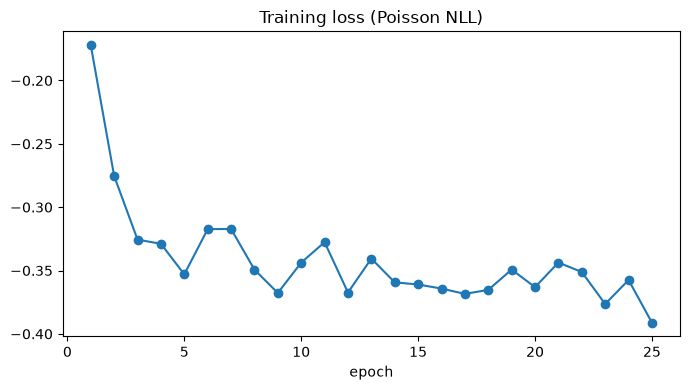

In [9]:
h = pd.DataFrame(history).set_index("epoch")
ax = h["train_loss"].plot(figsize=(7, 4), title="Training loss (Poisson NLL)", marker="o")
plt.tight_layout(); plt.show()

## 8. Test on d_1554 – d_1941
The model never saw these days. It forecasts them in rolling 28-day blocks, each using the actual history up to the block's start, with the weights frozen after training.

In [10]:
pred_test = rolling(predict)
results["LSTM encoder-decoder"] = evaluate(pred_test)
res = pd.DataFrame(results).T.sort_values("WRMSSE")
display(res.style.format("{:.4f}"))

by_level = pd.DataFrame({
    "LSTM": wr_test.score(pred_test, Y_test, by_level=True),
    "Seasonal naive": wr_test.score(baseline_preds["Seasonal naive (repeat last week)"], Y_test, by_level=True),
})
by_level.style.format("{:.3f}")

,WRMSSE,RMSE,R²,MAPE % (sales>0),Total RMSE,Total R²,Total MAPE % (excl. Xmas)
LSTM encoder-decoder,0.6597,2.1862,0.6362,56.5746,2809.4457,0.8267,5.0813
Seasonal naive (repeat last week),0.9743,2.8755,0.3706,85.3033,4714.3357,0.5121,8.7413
28-day moving average,1.0829,2.3536,0.5783,60.3431,6553.9400,0.0570,12.4427
Naive (repeat last day),1.4075,2.8561,0.3790,83.4165,8940.5520,-0.7548,15.7723


,LSTM,Seasonal naive
Total,0.491,0.824
State,0.532,0.854
Store,0.574,0.907
Category,0.540,0.875
Dept,0.595,0.949
State×Cat,0.592,0.912
State×Dept,0.644,0.973
Store×Cat,0.644,0.972
Store×Dept,0.698,1.023
Item,0.918,1.171


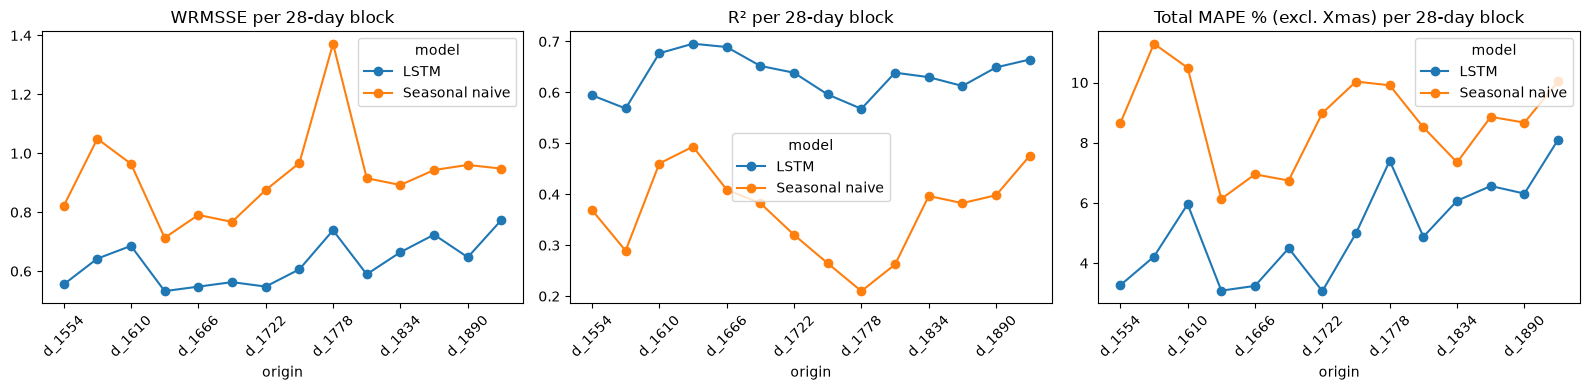

WRMSSE                  RMSE                    R²                 \
model    LSTM Seasonal naive   LSTM Seasonal naive   LSTM Seasonal naive   
origin                                                                     
d_1554  0.555          0.821  2.162          2.696  0.594          0.369   
d_1582  0.642          1.049  2.454          3.149  0.568          0.289   
d_1610  0.686          0.964  2.200          2.843  0.677          0.460   
d_1638  0.532          0.713  2.162          2.788  0.696          0.494   
d_1666  0.547          0.791  2.083          2.871  0.689          0.409   
d_1694  0.563          0.767  2.176          2.898  0.652          0.382   
d_1722  0.548          0.875  2.074          2.844  0.639          0.320   
d_1750  0.606          0.967  2.187          2.950  0.596          0.265   
d_1778  0.739          1.372  2.207          2.984  0.568          0.210   
d_1806  0.589          0.915  2.077          2.968  0.639          0.262   
d_1834  0.664          0.892  2.252          2.875  0.630          0.397   
d_1862  0.724          0.943  2.245          2.834  0.613          0.383   
d_1890  0.647          0.960  2.134          2.794  0.649          0.398   
d_1918  0.774          0.948  2.163          2.705  0.665          0.476   

       Total MAPE % (excl. Xmas)                 
model                       LSTM Seasonal naive  
origin                                           
d_1554                     3.264          8.646  
d_1582                     4.217         11.289  
d_1610                     5.958         10.490  
d_1638                     3.086          6.135  
d_1666                     3.244          6.950  
d_1694                     4.494          6.744  
d_1722                     3.071          8.986  
d_1750                     4.994         10.032  
d_1778                     7.401          9.908  
d_1806                     4.877          8.511  
d_1834                     6.072          7.348  
d_1862                     6.562          8.860  
d_1890                     6.311          8.669  
d_1918                     8.101         10.036

In [11]:
# Metrics per 28-day block: does accuracy drift as the test period gets further from the training data?
rows = []
for o in ORIGINS:
    s = slice(o - TRAIN_END, min(o + HORIZON, TEST_END) - TRAIN_END)
    for name, p in [("LSTM", pred_test), ("Seasonal naive", baseline_preds["Seasonal naive (repeat last week)"])]:
        m = evaluate(p[:, s], Y_test[:, s], days=s)
        rows.append({"origin": f"d_{o + 1}", "model": name, **m})
blocks = pd.DataFrame(rows)

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col in zip(axes, ["WRMSSE", "R²", "Total MAPE % (excl. Xmas)"]):
    blocks.pivot(index="origin", columns="model", values=col).plot(ax=ax, marker="o", title=f"{col} per 28-day block")
    ax.tick_params(axis="x", rotation=45)
plt.tight_layout(); plt.show()
blocks.pivot(index="origin", columns="model", values=["WRMSSE", "RMSE", "R²", "Total MAPE % (excl. Xmas)"]).round(3)

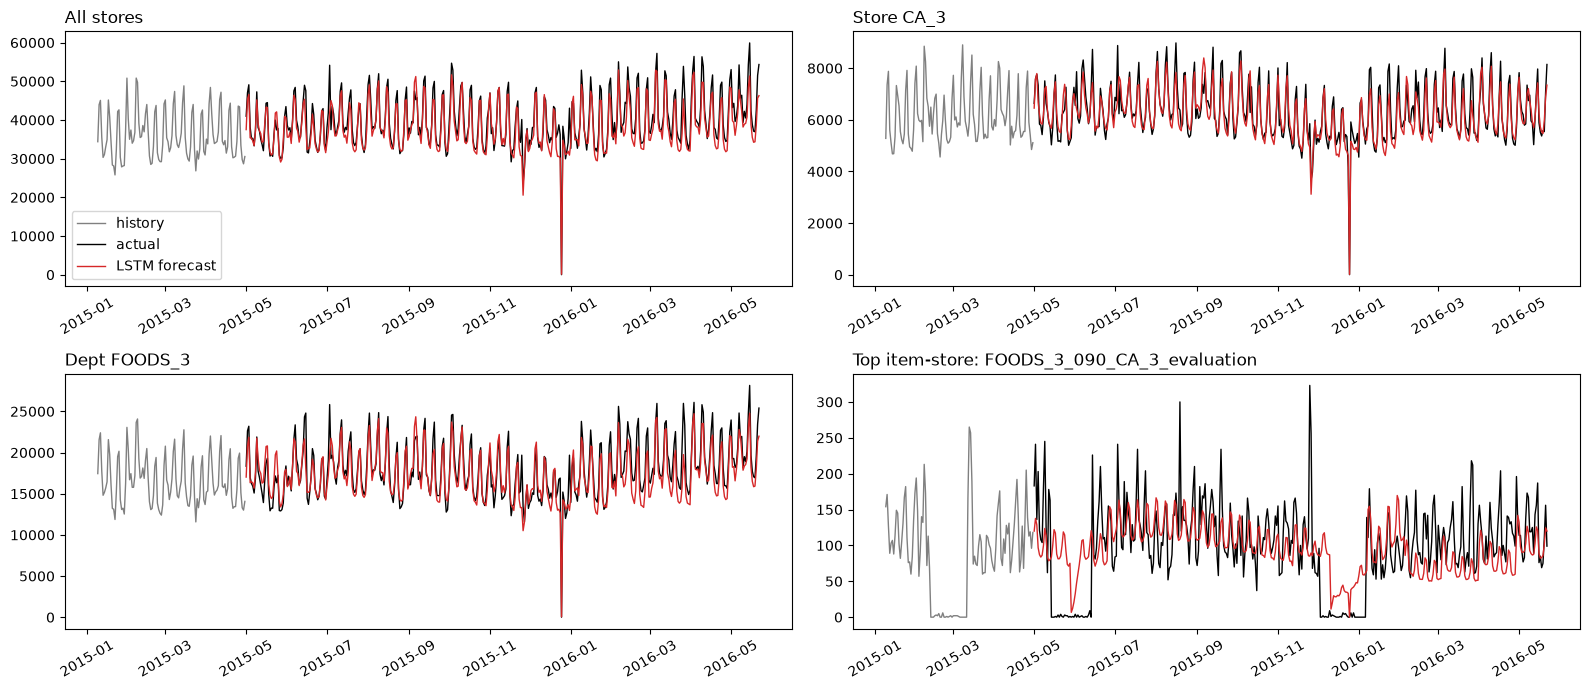

In [12]:
fig, axes = plt.subplots(2, 2, figsize=(16, 7))
test_dates = calendar["date"].iloc[TRAIN_END:TEST_END]
hist_dates = calendar["date"].iloc[TRAIN_END - 112:TRAIN_END]

def plot(ax, mask, title):
    ax.plot(hist_dates, Y[mask, TRAIN_END - 112:TRAIN_END].sum(0), c="grey", lw=1, label="history")
    ax.plot(test_dates, Y_test[mask].sum(0), c="k", lw=1, label="actual")
    ax.plot(test_dates, pred_test[mask].sum(0), c="C3", lw=1, label="LSTM forecast")
    ax.set_title(title, loc="left"); ax.tick_params(axis="x", rotation=30)

plot(axes[0, 0], np.ones(N, bool), "All stores")
plot(axes[0, 1], (sales["store_id"] == "CA_3").to_numpy(), "Store CA_3")
plot(axes[1, 0], (sales["dept_id"] == "FOODS_3").to_numpy(), "Dept FOODS_3")
top = Y[:, TRAIN_END - 28:TRAIN_END].sum(1).argmax()
plot(axes[1, 1], np.arange(N) == top, f"Top item-store: {sales['id'].iloc[top]}")
axes[0, 0].legend(); plt.tight_layout(); plt.show()

## 9. Save outputs
- `outputs/lstm_d1553_test_preds.csv`: forecasts for d_1554 – d_1941 for each `id` (one column per day). Use these to compare with, or blend into, the regression and XGBoost models on the same split.
- `outputs/lstm_d1553_metrics.csv`: the results table above.
- `outputs/lstm_d1553_model.pt`: model weights.

In [13]:
d_cols = [f"d_{k}" for k in range(TRAIN_END + 1, TEST_END + 1)]
pd.DataFrame(pred_test, columns=d_cols).assign(id=sales["id"].values)[["id"] + d_cols] \
  .to_csv(f"{OUT}/lstm_d1553_test_preds.csv", index=False)
res.to_csv(f"{OUT}/lstm_d1553_metrics.csv")
torch.save(model.state_dict(), f"{OUT}/lstm_d1553_model.pt")
print("saved:", os.listdir(OUT))

saved: ['lstm_d1553_metrics.csv', 'lstm_d1553_model.pt', 'lstm_d1553_test_preds.csv', 'lstm_model.pt', 'lstm_submission.csv', 'lstm_test_preds.csv']


## 10. Ideas to improve
- **Epoch count:** without a validation set, `EPOCHS` is a fixed guess. A time-based validation block carved from the end of training (e.g. d_1526 – d_1553) would let you tune it without touching the test period.
- **Retrain as the origin moves:** the weights are frozen at d_1553, so later blocks are forecast by an increasingly stale model. Periodic refits (e.g. every 3 months) would show how much that costs.
- **Ensemble:** average several runs with different seeds or encoder lengths (56/112/224 days). Blend with the team's XGBoost predictions using `lstm_d1553_test_preds.csv`.
- **Loss:** try a Tweedie loss, or weight each series in the loss by its WRMSSE weight so training targets the metric directly.
- **Features:** add sales from the same days last year (365-day lag), rolling-window statistics, and price relative to the department.